<a href="https://colab.research.google.com/github/Heitor65/Fall_Detection-Sistemas_Embarcados/blob/master/FallDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Links importantes:
- https://sol.sbc.org.br/index.php/wvc/article/view/18899/18729
- https://data.mendeley.com/datasets/6fhphxg297/2
- https://datadryad.org/dataset/doi:10.5061/dryad.41ns1rnj3
- https://www.sdp8.net/Dataset?id=dfe4621e-4774-4ef4-b064-e4a082c12335

In [1]:
!curl -LsSf https://astral.sh/uv/install.sh | sh

downloading uv 0.13.7 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!


In [2]:
!uv init

Initialized project `content`


In [3]:
!add-apt-repository ppa:git-core/ppa
!apt update; apt install git

PPA publishes dbgsym, you may need to include 'main/debug' component
Repository: 'Types: deb
URIs: https://ppa.launchpadcontent.net/git-core/ppa/ubuntu/
Suites: noble
Components: main
'
Description:
The most current stable version of Git for Ubuntu.

For release candidates, go to https://launchpad.net/~git-core/+archive/candidate .
More info: https://launchpad.net/~git-core/+archive/ubuntu/ppa
Adding repository.
Press [ENTER] to continue or Ctrl-c to cancel.
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,172 kB]
Get:8 http://archive.ubuntu.com/ubun

In [4]:
!uv add scikit-learn

Using CPython 3.13.18 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 8 packages in 176ms
Prepared 8 packages in 301ms
Installed 8 packages in 28ms
 + cloudpickle==3.1.2
 + content==0.1.0 (from file:///content)
 + joblib==1.6.0
 + narwhals==2.28.0
 + numpy==2.5.4
 + scikit-learn==1.9.1
 + scipy==1.18.1
 + threadpoolctl==3.7.0


## Download Dataset
- Adiquira o link de download, pelo DevTools caso o sdp8 e cole no curl, e extraia na pasta "csi-bench".





In [5]:
!pwd
!mkdir datasets
%cd datasets


/content
/content/datasets


In [6]:
!git clone https://github.com/junnn0098/26_HS022.git

Cloning into '26_HS022'...
remote: Enumerating objects: 1191, done.
remote: Counting objects: 100% (1191/1191), done.
remote: Compressing objects: 100% (740/740), done.
remote: Total 1191 (delta 413), reused 1077 (delta 348), pack-reused 0 (from 0)
Receiving objects: 100% (1191/1191), 37.51 MiB | 31.00 MiB/s, done.
Resolving deltas: 100% (413/413), done.


In [7]:
!uv run 26_HS022/dataset/tools/download.py

downloading  https://github.com/junnn0098/26_HS022/releases/download/dataset-v1.0/csi134_b1_0708_0709.npz
     89.3 / 89.3 MB
ok           csi134_b1_0708_0709.npz
downloading  https://github.com/junnn0098/26_HS022/releases/download/dataset-v1.0/csi134_b2_0715.npz
     40.4 / 40.4 MB
ok           csi134_b2_0715.npz
downloading  https://github.com/junnn0098/26_HS022/releases/download/dataset-v1.0/csi134_b3_0724.npz
     34.9 / 34.9 MB
ok           csi134_b3_0724.npz
downloading  https://github.com/junnn0098/26_HS022/releases/download/dataset-v1.0/csi134_b4_0728.npz
     24.3 / 24.3 MB
ok           csi134_b4_0728.npz


In [ ]:
!while [ "$(find . -name "*.zip")" ]; do find . -name "*.zip" -exec unzip -o {} \; -exec rm {} \;; done


# Modelo


## Preparação Dataset


In [8]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# --- 1. Preparação dos Caminhos e Metadados ---
paths = [
    "/content/datasets/26_HS022/dataset/data/csi134_b1_0708_0709.npz",
    "/content/datasets/26_HS022/dataset/data/csi134_b2_0715.npz",
    "/content/datasets/26_HS022/dataset/data/csi134_b3_0724.npz",
    "/content/datasets/26_HS022/dataset/data/csi134_b4_0728.npz"
]

# Ler o CSV utilizando pandas para garantir o mapeamento seguro
caminho_csv = "/content/datasets/26_HS022/dataset/metadata/windows.csv"
df_windows = pd.read_csv(caminho_csv)
particao_dataset: float = 0.7

# --- 2. Função de Extração de Características ---
def calcula_parametros(janela) -> np.ndarray:
    # Características Temporais
    media = np.mean(janela, axis=0)
    desv_pad = np.std(janela, axis=0)
    amplitude = np.max(janela, axis=0) - np.min(janela, axis=0)
    variancia = np.var(janela, axis=0)

    coef_variacao = np.divide(
        desv_pad * 100, media,
        out=np.zeros_like(media, dtype=float),
        where=(media != 0),
    )

    # Características de Frequência (FFT)
    fft_vals = np.fft.rfft(janela, axis=0)
    fft_magnitudes = np.abs(fft_vals)

    energia_espectral = np.sum(fft_magnitudes ** 2, axis=0) / len(janela)
    pico_fft = np.max(fft_magnitudes, axis=0)
    media_fft = np.mean(fft_magnitudes, axis=0)

    # Combinação num único vetor 1D
    vetor = np.concatenate([
        media, desv_pad, amplitude, variancia, coef_variacao,
        energia_espectral, pico_fft, media_fft
    ])
    return vetor

# --- 3. Processamento do Dataset ---
x_treino = []
y_treino = []
x_teste = []
y_teste = []

for path in paths:
    npz_archive = np.load(path)
    X_data = npz_archive['X']
    qtd_janelas = len(X_data)
    limite_janelas_validacao = int(qtd_janelas * particao_dataset)

    # Isolar o nome do ficheiro para filtrar o DataFrame (ex: 'csi134_b1_0708_0709.npz')
    nome_ficheiro_npz = path.split('/')[-1]
    df_filtrado = df_windows[df_windows['npz_file'] == nome_ficheiro_npz]

    # Extração para Treino (do início até ao limite)
    for idx, janela in enumerate(X_data[:limite_janelas_validacao]):
        vetor_x = calcula_parametros(janela)
        # Obter o gabarito garantindo que o npz_index corresponde ao idx do ficheiro
        gabarito = df_filtrado.loc[df_filtrado['npz_index'] == idx, 'is_fall'].values[0]

        x_treino.append(vetor_x)
        y_treino.append(gabarito)

    # Extração para Teste (do limite até ao fim)
    for idx_relativo, janela in enumerate(X_data[limite_janelas_validacao:]):
        vetor_x = calcula_parametros(janela)
        # O índice original no ficheiro .npz é o limite mais a posição atual no teste
        idx_real = limite_janelas_validacao + idx_relativo
        gabarito = df_filtrado.loc[df_filtrado['npz_index'] == idx_real, 'is_fall'].values[0]

        x_teste.append(vetor_x)
        y_teste.append(gabarito)

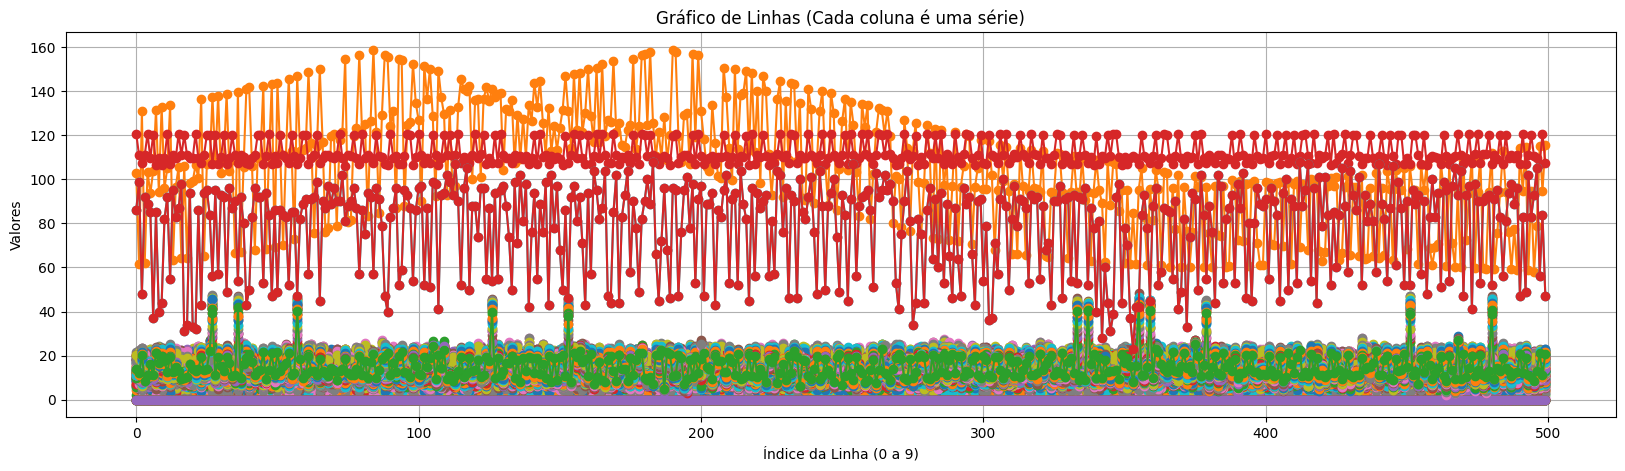

In [ ]:
janela_fall = npz_archive['X'][188]
plt.figure(figsize=(20, 5))  # Deixa o gráfico mais largo para respirar

plt.plot(janela_fall, marker='o')
plt.title('Gráfico de Linhas (Cada coluna é uma série)')
plt.xlabel('Índice da Linha (0 a 9)')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

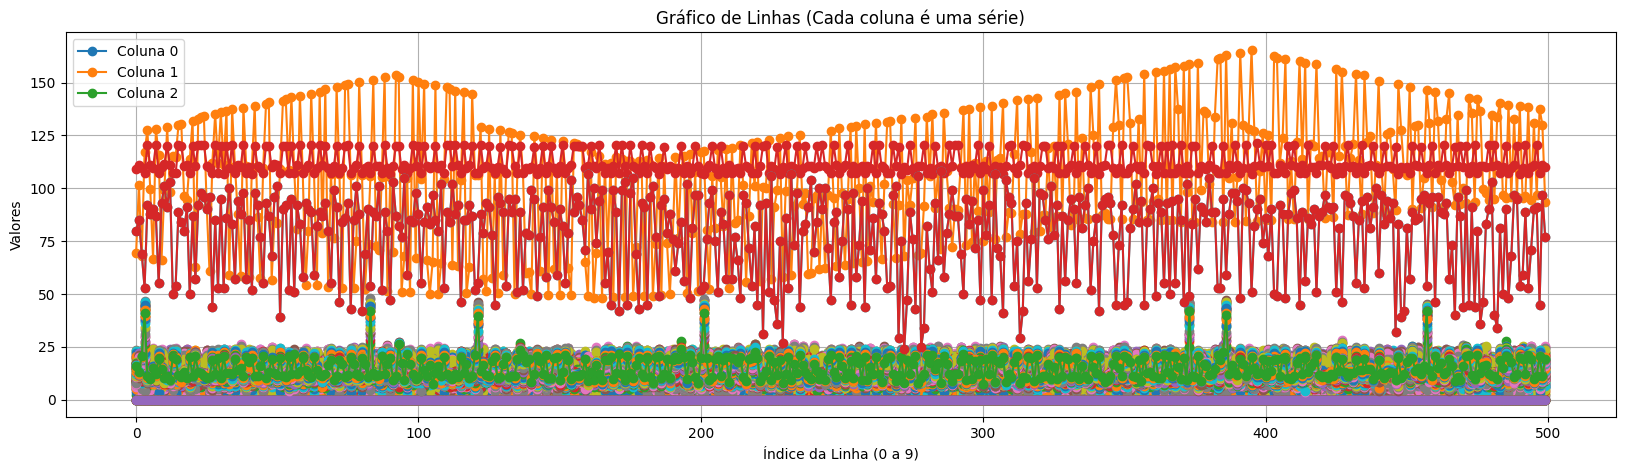

In [ ]:
janela_fall = npz_archive['X'][200]
plt.figure(figsize=(20, 5))  # Deixa o gráfico mais largo para respirar

plt.plot(janela_fall, marker='o')
plt.title('Gráfico de Linhas (Cada coluna é uma série)')
plt.xlabel('Índice da Linha (0 a 9)')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

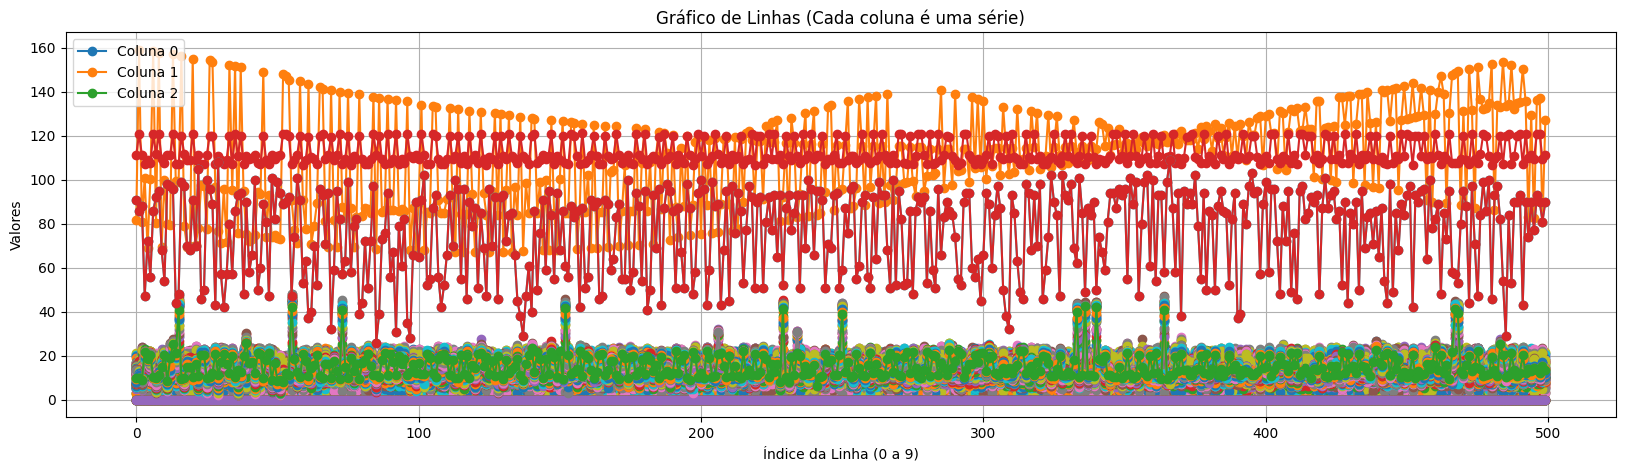

In [ ]:
janela_walking = npz_archive['X'][209]
plt.figure(figsize=(20, 5))  # Deixa o gráfico mais largo para respirar

plt.plot(janela_walking, marker='o')
plt.title('Gráfico de Linhas (Cada coluna é uma série)')
plt.xlabel('Índice da Linha (0 a 9)')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

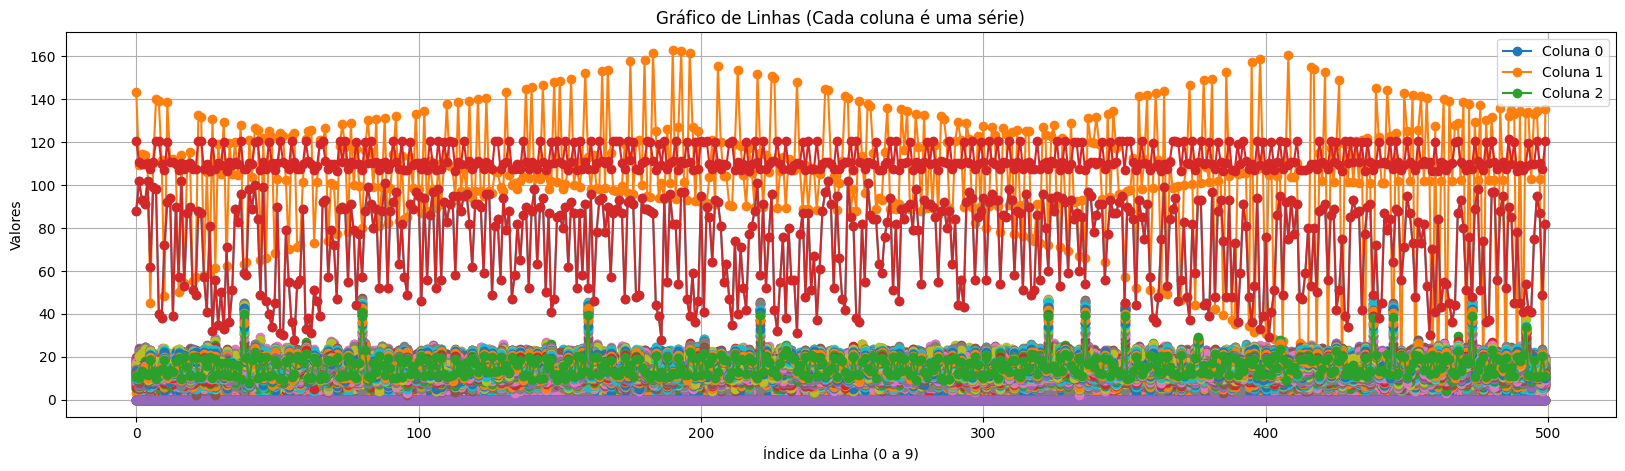

In [ ]:
janela_walking = npz_archive['X'][0]
plt.figure(figsize=(20, 5))  # Deixa o gráfico mais largo para respirar

plt.plot(janela_walking, marker='o')
plt.title('Gráfico de Linhas (Cada coluna é uma série)')
plt.xlabel('Índice da Linha (0 a 9)')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

## Treinamento

In [9]:
# Treinamento
# 1. Importar o modelo do Scikit-Learn
from sklearn.ensemble import RandomForestClassifier

# --- 4. Treino do Modelo ---
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(x_treino, y_treino)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [ ]:
# @title
from sklearn.ensemble import HistGradientBoostingClassifier

modelo = HistGradientBoostingClassifier(
    max_iter=100,
    max_depth=None,      # Deixa crescer livre igual ao Random Forest
    learning_rate=0.1,
    random_state=42
)

modelo.fit(x, y)
print("Gradient Boosting treinado com sucesso!")

Gradient Boosting treinado com sucesso!


In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# 1. Definir os modelos base que vão palpitar juntos
modelos_base = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42))
]

# 2. O meta-modelo (juiz final) que combina os palpites
meta_modelo = LogisticRegression()

# 3. Criar o classificador empilhado
modelo = StackingClassifier(
    estimators=modelos_base,
    final_estimator=meta_modelo,
    cv=5
)

# 4. O resto do código (fit e teste) continua exatamente igual!
modelo.fit(x, y)
print("Stacking treinado com sucesso!")

## Teste

In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score

# 1. O modelo prevê todas as janelas de teste de uma só vez (muito mais rápido)
previsoes = modelo.predict(x_teste)

# 2. A matriz de confusão retorna 4 valores na seguinte ordem:
# Verdadeiro Negativo (VN), Falso Positivo (FP), Falso Negativo (FN), Verdadeiro Positivo (VP)
vn, fp, fn, vp = confusion_matrix(y_teste, previsoes).ravel()

# 3. Recálculo das suas métricas
qtd_testes = len(y_teste)
acertos = vn + vp
erros = fp + fn

acuracia = acertos / qtd_testes
taxa_erros = erros / qtd_testes

# Calcula a proporção usando validação para evitar divisão por zero caso o modelo acerte tudo
perc_falsos_positivos = fp / erros if erros > 0 else 0
perc_falsos_negativos = fn / erros if erros > 0 else 0

print(f"Acurácia: {acuracia:.2%}")
print(f"Erros Totais: {taxa_erros:.2%}")
print(f"Dos erros, {perc_falsos_positivos:.2%} foram Falsos Positivos (Alarme Falso)")
print(f"Dos erros, {perc_falsos_negativos:.2%} foram Falsos Negativos (Queda Ignorada)")

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. Avaliação Detalhada (Precisão, Recall, F1-Score)
previsoes = modelo.predict(x_teste)

print("\n--- Relatório de Classificação ---")
print(classification_report(y_teste, previsoes, target_names=['Normal (0)', 'Queda (1)']))

print("\n--- Matriz de Confusão ---")
print(confusion_matrix(y_teste, previsoes))

Acurácia: 65.97%
Erros Totais: 34.03%
Dos erros, 42.29% foram Falsos Positivos (Alarme Falso)
Dos erros, 57.71% foram Falsos Negativos (Queda Ignorada)

--- Relatório de Classificação ---
              precision    recall  f1-score   support

  Normal (0)       0.68      0.74      0.71       375
   Queda (1)       0.63      0.55      0.59       292

    accuracy                           0.66       667
   macro avg       0.65      0.65      0.65       667
weighted avg       0.66      0.66      0.66       667


--- Matriz de Confusão ---
[[279  96]
 [131 161]]
